# Exploratory Data Analysis

## Project goal

Understand purchasing behavior and identify actionable opportunities in the Olist marketplace.

## Business questions

1. How has revenue and order volume changed over time?
2. Which product categories contribute the most revenue?
3. How common are repeat purchases?
4. How do delivery performance and review scores interact?
5. Which states and sellers have the largest completed-order activity?
6. How does payment behavior vary across orders?

## Metric definitions

- **Completed order:** `order_status == "delivered"`
- **Revenue:** sum of item `price`; freight is excluded unless otherwise stated
- **Customer:** `customer_unique_id`
- **Repeat customer:** a customer with more than one completed order
- **Dataset period:** purchase timestamp range in the source data

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path("../data/raw")

customers = pd.read_csv(DATA_DIR / "olist_customers_dataset.csv")
orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
order_items = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
payments = pd.read_csv(DATA_DIR / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(DATA_DIR / "olist_order_reviews_dataset.csv")
products = pd.read_csv(DATA_DIR / "olist_products_dataset.csv")
sellers = pd.read_csv(DATA_DIR / "olist_sellers_dataset.csv")
category_translation = pd.read_csv(DATA_DIR / "product_category_name_translation.csv")

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

orders["purchase_month"] = orders["order_purchase_timestamp"].dt.to_period("M").astype(str)
orders["delivery_days"] = (
    orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

completed_orders = orders.loc[orders["order_status"] == "delivered"].copy()
print("Dataset period:", completed_orders["order_purchase_timestamp"].min(), "to", completed_orders["order_purchase_timestamp"].max())
print("Completed orders:", f"{len(completed_orders):,}")
print("All source orders:", f"{len(orders):,}")

Dataset period: 2016-09-15 12:16:38 to 2018-08-29 15:00:37
Completed orders: 96,478
All source orders: 99,441


## 1. Revenue and order trends

Monthly trends should use delivered orders to avoid counting orders that were canceled or never fulfilled.

,purchase_month,revenue,orders,average_order_value
11,2017-09,607399.67,4150,146.361366
12,2017-10,648247.65,4478,144.762762
13,2017-11,987765.37,7289,135.514525
14,2017-12,726033.19,5513,131.694756
15,2018-01,924645.00,7069,130.802801
16,2018-02,826437.13,6555,126.077365
17,2018-03,953356.25,7003,136.135406
18,2018-04,973534.09,6798,143.208898
19,2018-05,977544.69,6749,144.842894
20,2018-06,856077.86,6099,140.363643


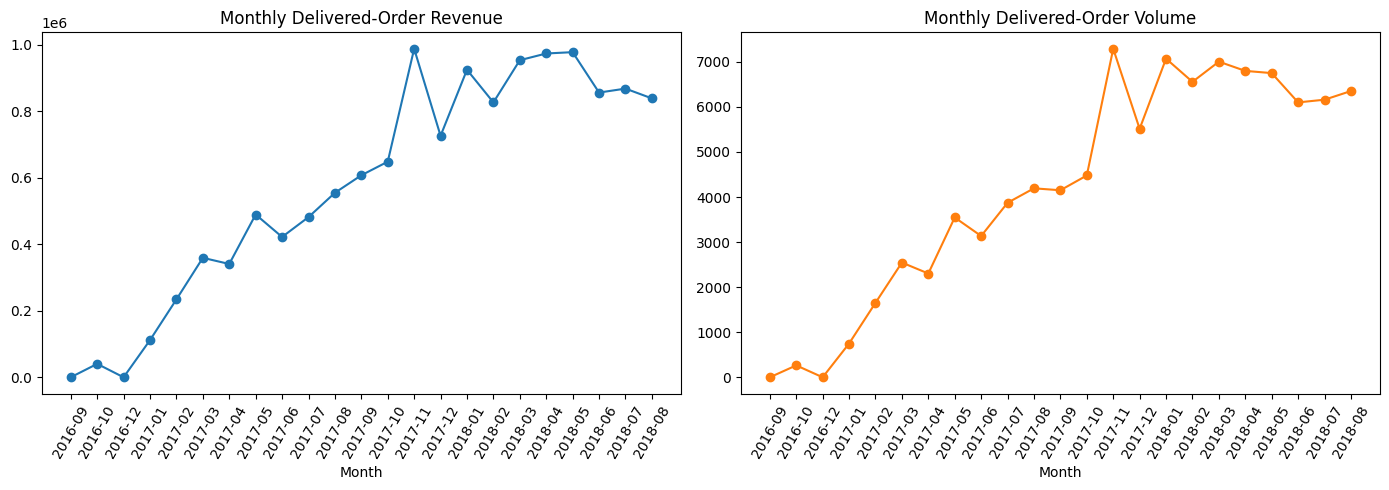

In [7]:
order_revenue = (
    order_items.groupby("order_id", as_index=False)["price"]
    .sum()
    .rename(columns={"price": "order_revenue"})
)

delivered = completed_orders.merge(
    order_revenue,
    on="order_id",
    how="left",
    validate="one_to_one",
)

monthly = (
    delivered.groupby("purchase_month", as_index=False)
    .agg(
        revenue=("order_revenue", "sum"),
        orders=("order_id", "nunique"),
    )
)
monthly["average_order_value"] = monthly["revenue"] / monthly["orders"]
display(monthly.tail(12))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(monthly["purchase_month"], monthly["revenue"], marker="o")
axes[0].set_title("Monthly Delivered-Order Revenue")
axes[0].set_xlabel("Month")
axes[0].tick_params(axis="x", rotation=60)

axes[1].plot(monthly["purchase_month"], monthly["orders"], marker="o", color="tab:orange")
axes[1].set_title("Monthly Delivered-Order Volume")
axes[1].set_xlabel("Month")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

## 2. Category performance

Revenue is measured by item price rather than payment value. A category is therefore assigned based on the product purchased.

,product_category_name_english,revenue,orders,items,revenue_percent
43,health_beauty,1233131.72,8647,9465,9.45
70,watches_gifts,1166176.98,5495,5859,8.94
7,bed_bath_table,1023434.76,9272,10953,7.85
65,sports_leisure,954852.55,7530,8431,7.32
15,computers_accessories,888724.61,6530,7644,6.81
39,furniture_decor,711927.69,6307,8160,5.46
49,housewares,615628.69,5743,6795,4.72
20,cool_stuff,610204.10,3559,3718,4.68
5,auto,578966.65,3810,4140,4.44
69,toys,471286.48,3804,4030,3.61


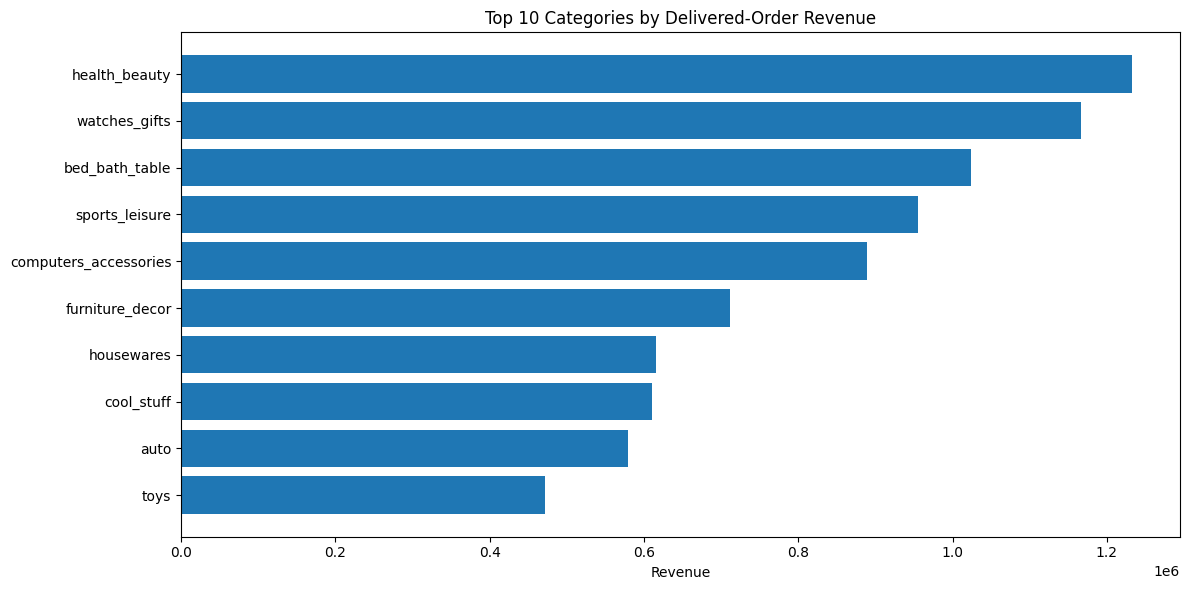

In [8]:
category_items = (
    order_items.merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        category_translation,
        on="product_category_name",
        how="left",
        validate="many_to_one",
    )
)

category_performance = (
    category_items.merge(
        completed_orders[["order_id"]],
        on="order_id",
        how="inner",
        validate="many_to_one",
    )
    .groupby("product_category_name_english", as_index=False)
    .agg(
        revenue=("price", "sum"),
        orders=("order_id", "nunique"),
        items=("order_item_id", "count"),
    )
    .sort_values("revenue", ascending=False)
)
category_performance["revenue_percent"] = (
    100 * category_performance["revenue"] / category_performance["revenue"].sum()
).round(2)

top_categories = category_performance.head(10)
display(top_categories)

plt.figure(figsize=(12, 6))
plt.barh(top_categories["product_category_name_english"], top_categories["revenue"])
plt.gca().invert_yaxis()
plt.title("Top 10 Categories by Delivered-Order Revenue")
plt.xlabel("Revenue")
plt.tight_layout()
plt.show()

## 3. Repeat purchasing

The customer-level unit of analysis is `customer_unique_id`. `customer_id` is order-specific and would incorrectly show every customer as a one-time buyer.

Customers: 93,358
Repeat customers: 2,801
Repeat customer rate: 3.00%


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
customer_unique_id,93358,93358,ffffd2657e2aad2907e67c3e9daecbeb,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_count,93358.0,NaN,NaN,NaN,1.03342,1.0,1.0,1.0,1.0,15.0,0.209097
total_revenue,93358.0,NaN,NaN,NaN,141.62148,0.85,47.65,89.73,154.7375,13440.0,215.694014
first_order,93358,NaN,NaN,NaN,2018-01-01 12:18:32.380503296,2016-09-15 12:16:38,2017-09-13 15:41:22.500000,2018-01-20 06:48:07,2018-05-05 14:13:38.249999872,2018-08-29 15:00:37,NaN
last_order,93358,NaN,NaN,NaN,2018-01-04 03:47:36.045363200,2016-09-15 12:16:38,2017-09-17 18:25:15,2018-01-23 00:12:12.500000,2018-05-07 17:22:34.750000128,2018-08-29 15:00:37,NaN
customer_state,93358,27,SP,39145,NaN,NaN,NaN,NaN,NaN,NaN,NaN
repeat_customer,93358,2,False,90557,NaN,NaN,NaN,NaN,NaN,NaN,NaN
average_order_value,93358.0,NaN,NaN,NaN,137.508262,0.85,46.0,86.99,149.9,13440.0,209.860279


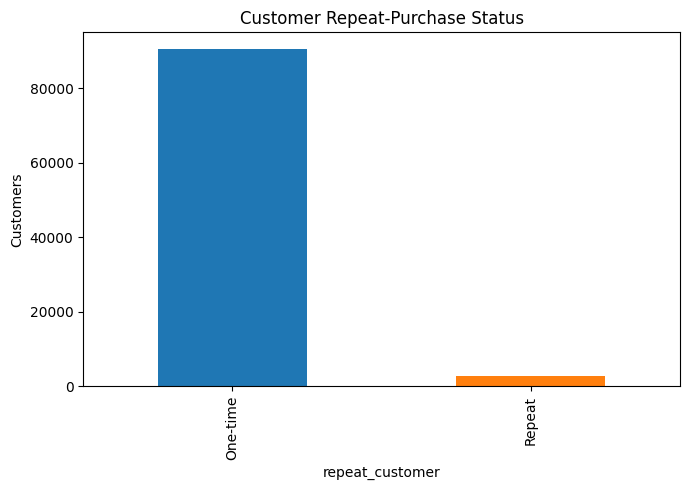

In [9]:
customer_orders = (
    completed_orders.merge(
        customers[["customer_id", "customer_unique_id", "customer_state", "customer_city"]],
        on="customer_id",
        how="left",
        validate="many_to_one",
    )
)

customer_summary = (
    customer_orders.merge(order_revenue, on="order_id", how="left", validate="one_to_one")
    .groupby("customer_unique_id", as_index=False)
    .agg(
        order_count=("order_id", "nunique"),
        total_revenue=("order_revenue", "sum"),
        first_order=("order_purchase_timestamp", "min"),
        last_order=("order_purchase_timestamp", "max"),
        customer_state=("customer_state", "last"),
    )
)
customer_summary["repeat_customer"] = customer_summary["order_count"] > 1
customer_summary["average_order_value"] = (
    customer_summary["total_revenue"] / customer_summary["order_count"]
)

repeat_count = int(customer_summary["repeat_customer"].sum())
customer_count = len(customer_summary)
repeat_rate = 100 * repeat_count / customer_count

print(f"Customers: {customer_count:,}")
print(f"Repeat customers: {repeat_count:,}")
print(f"Repeat customer rate: {repeat_rate:.2f}%")
display(customer_summary.describe(include="all").T)

plt.figure(figsize=(7, 5))
customer_summary["repeat_customer"].value_counts().sort_index().plot(
    kind="bar",
    color=["tab:blue", "tab:orange"],
)
plt.xticks([0, 1], ["One-time", "Repeat"])
plt.title("Customer Repeat-Purchase Status")
plt.ylabel("Customers")
plt.tight_layout()
plt.show()

## 4. Delivery performance and reviews

Only delivered orders with an actual customer delivery timestamp should be included in delivery-duration analysis. Some orders have multiple review records, so the latest submitted review is used to keep one review per order.

Delivery days summary:


count    95824.000000
mean        12.516765
std          9.460505
min          0.533414
25%          6.757214
50%         10.206059
75%         15.663542
max        208.351759
Name: delivery_days, dtype: float64

,review_score,orders,average_delivery_days
0,1,9353,21.324741
1,2,2919,16.627387
2,3,7916,14.256235
3,4,18894,12.305959
4,5,56742,10.680972


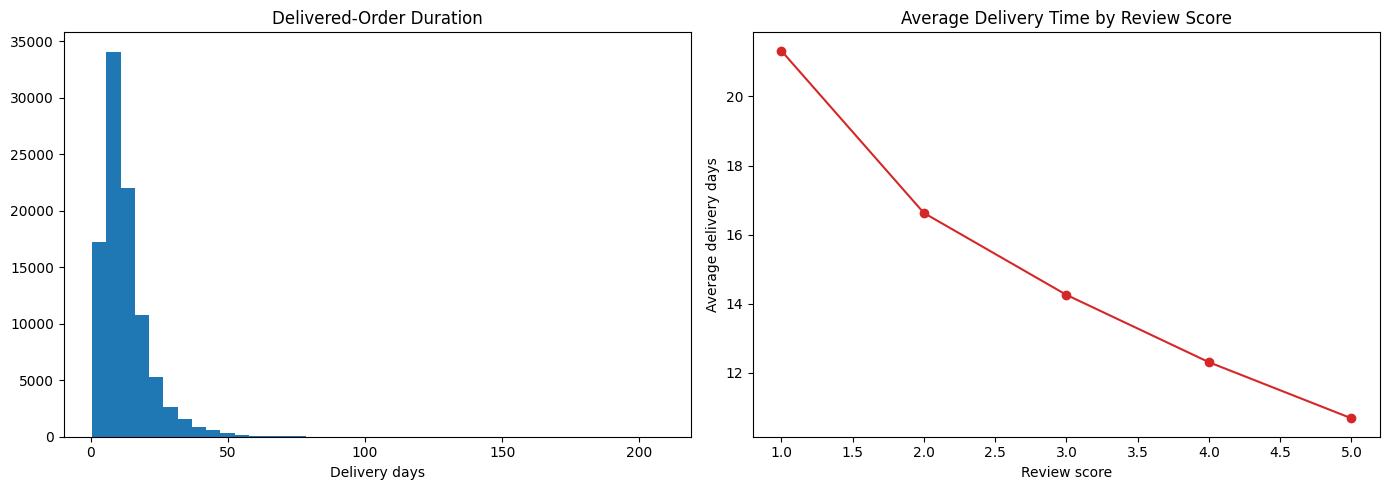

In [10]:
latest_reviews = (
    reviews.sort_values(["review_creation_date", "review_answer_timestamp"])
    .drop_duplicates(subset="order_id", keep="last")
)

delivery_reviews = (
    completed_orders[["order_id", "delivery_days"]]
    .merge(latest_reviews[["order_id", "review_score"]], on="order_id", how="inner", validate="one_to_one")
)

delivery_reviews = delivery_reviews.dropna(subset=["delivery_days", "review_score"])
print("Delivery days summary:")
display(delivery_reviews["delivery_days"].describe())

score_delivery = (
    delivery_reviews.groupby("review_score", as_index=False)
    .agg(
        orders=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean"),
    )
)
display(score_delivery)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(delivery_reviews["delivery_days"], bins=40, color="tab:blue")
axes[0].set_title("Delivered-Order Duration")
axes[0].set_xlabel("Delivery days")

axes[1].plot(
    score_delivery["review_score"],
    score_delivery["average_delivery_days"],
    marker="o",
    color="tab:red",
)
axes[1].set_title("Average Delivery Time by Review Score")
axes[1].set_xlabel("Review score")
axes[1].set_ylabel("Average delivery days")

plt.tight_layout()
plt.show()

## 5. Geographic concentration

Customer states are evaluated using completed orders and a customer-to-order join.

,customer_state,customers,orders,revenue
25,SP,39156,40501,5067633.16
18,RJ,11917,12350,1759651.13
10,MG,11001,11354,1552481.83
22,RS,5168,5345,728897.47
17,PR,4769,4923,666063.51
23,SC,3449,3546,507012.13
4,BA,3158,3256,493584.14
6,DF,2019,2080,296498.41
8,GO,1895,1957,282836.70
7,ES,1928,1995,268643.45


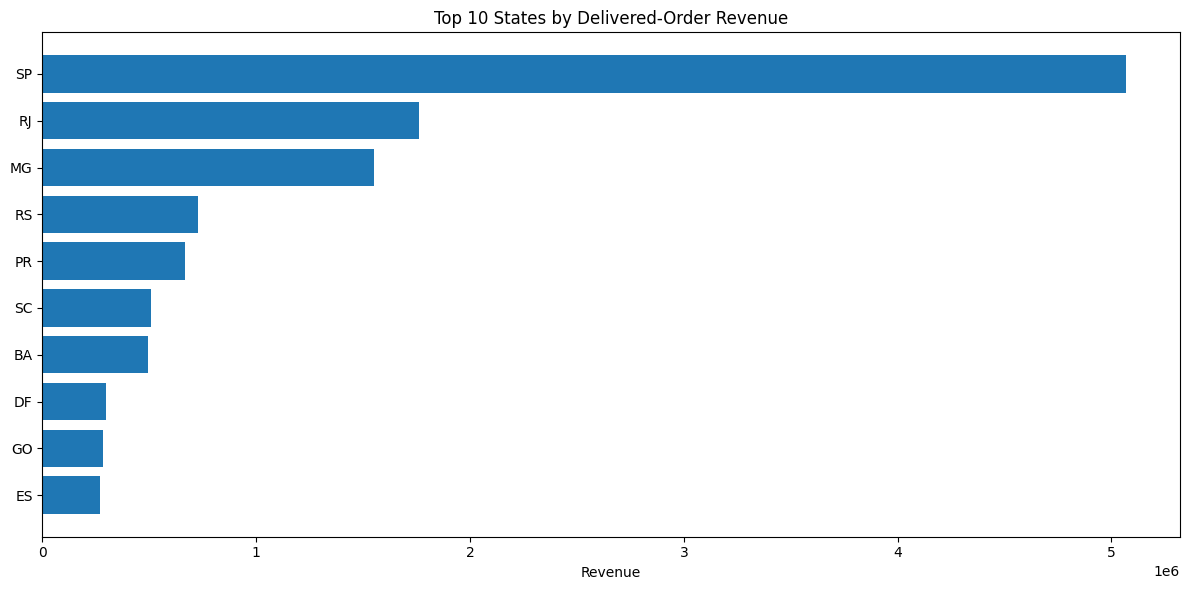

In [11]:
state_summary = (
    customer_orders.groupby("customer_state", as_index=False)
    .agg(
        customers=("customer_unique_id", "nunique"),
        orders=("order_id", "nunique"),
    )
    .merge(
        customer_orders.merge(order_revenue, on="order_id", validate="many_to_one")
        .groupby("customer_state", as_index=False)["order_revenue"]
        .sum(),
        on="customer_state",
        how="left",
    )
    .rename(columns={"order_revenue": "revenue"})
    .sort_values("revenue", ascending=False)
)
display(state_summary.head(15))

top_states = state_summary.head(10)
plt.figure(figsize=(12, 6))
plt.barh(top_states["customer_state"], top_states["revenue"])
plt.gca().invert_yaxis()
plt.title("Top 10 States by Delivered-Order Revenue")
plt.xlabel("Revenue")
plt.tight_layout()
plt.show()

## 6. Payment behavior

Payment rows can contain multiple records per order, so payment methods are summarized at order level.

,payment_type,payment_rows,orders,payment_value
1,credit_card,74586,74304,12101094.88
0,boleto,19191,19191,2769932.58
3,voucher,5493,3679,343013.19
2,debit_card,1486,1485,208421.12


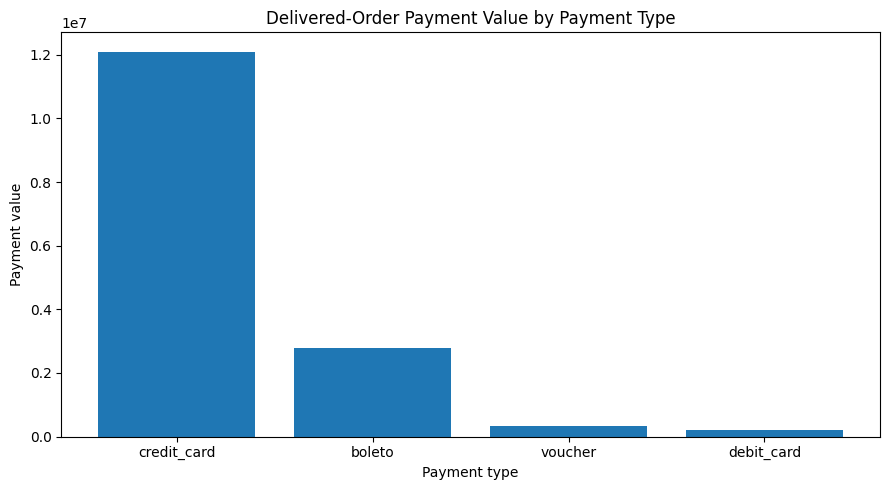

In [12]:
payment_summary = (
    payments.merge(completed_orders[["order_id"]], on="order_id", how="inner")
    .groupby("payment_type", as_index=False)
    .agg(
        payment_rows=("order_id", "count"),
        orders=("order_id", "nunique"),
        payment_value=("payment_value", "sum"),
    )
    .sort_values("payment_value", ascending=False)
)
display(payment_summary)

plt.figure(figsize=(9, 5))
plt.bar(payment_summary["payment_type"], payment_summary["payment_value"])
plt.title("Delivered-Order Payment Value by Payment Type")
plt.xlabel("Payment type")
plt.ylabel("Payment value")
plt.tight_layout()
plt.show()

## Key findings and recommendations

### Findings

1. **Revenue trend:** Delivered-order revenue and volume peaked in November 2017 at R$987,765 across 7,289 orders. From January through August 2018, monthly revenue ranged from about R$826,000 to R$978,000. The analysis covers delivered purchases from September 2016 through August 2018.

2. **Category concentration:** Health and beauty led item revenue at R$1.23M, followed by watches and gifts at R$1.17M and bed, bath, and table at R$1.02M. The five highest-revenue categories contributed 40.37% of category revenue.

3. **Repeat purchasing:** 2,801 of 93,358 customers with delivered orders made more than one purchase in the observed period (3.00%). These repeat customers generated 5.51% of item revenue.

4. **Delivery and reviews:** Average delivery time was 12.52 days (median 10.21). Orders with a one-star review averaged 21.32 delivery days, compared with 10.68 days for five-star reviews. Delivery time and review score had a moderate negative correlation (r = -0.334).

5. **Geography and payments:** Sao Paulo generated 38.33% of delivered-order revenue; Rio de Janeiro and Minas Gerais contributed 13.31% and 11.74%. Credit cards accounted for 78.46% of payment value, while boleto accounted for 17.96%.

### Recommended actions

- **Test second-purchase campaigns:** Target recently delivered first-time buyers with relevant follow-up offers, and measure incremental repeat orders against a holdout group.
- **Investigate delivery friction:** Break down late deliveries and low review scores by route, seller, and product category; prioritize the largest problem segments before changing delivery promises.
- **Prioritize category planning:** Protect availability in the leading categories, but validate margins, returns, and fulfillment costs before increasing promotions or inventory.
- **Focus regional operations:** Use Sao Paulo, Rio de Janeiro, and Minas Gerais as high-volume service areas; compare per-customer performance and delivery quality before expanding spend elsewhere.
- **Keep checkout aligned with observed behavior:** Maintain a reliable credit-card experience while preserving boleto as a meaningful alternative. Payment-type order shares can overlap when an order uses multiple payment methods.
- **Complete seller analysis:** The current notebook does not compare seller performance, so use seller-level delivery and review metrics before making seller-specific recommendations.

### Interpretation notes

- The repeat-purchase rate describes behavior observed from September 2016 through August 2018; customers had different amounts of time to purchase again, so it is not a lifetime churn rate.
- Revenue is the sum of item prices and excludes freight, costs, and profit margins. The delivery-review relationship is an association, not evidence that delivery time alone caused a review score.